<a href="https://colab.research.google.com/github/shreyasshikhare11/Many-Body-Localisation-in-a-quantum-simulator-with-programmable-random-disorder/blob/main/Many_body_localization_in_a_quantum_simulator_with_programmable_random_disorder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Many-body localization in a quantum simulator with programmable random disorder**

https://arxiv.org/pdf/1508.07026

In [1]:
!pip install qiskit
!pip install qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 15.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 27.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 26.4 MB/s  0:00:00


Phase 1: The Classical Baseline (Exact Diagonalization)

In [2]:
import numpy as np
import scipy.linalg as sla
from typing import List, Tuple, Optional

# Standard 2x2 Pauli Matrices
I2: np.ndarray = np.eye(2, dtype=np.complex128)
X: np.ndarray = np.array([[0.0, 1.0], [1.0, 0.0]], dtype=np.complex128)
Y: np.ndarray = np.array([[0.0, -1j], [1j, 0.0]], dtype=np.complex128)
Z: np.ndarray = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=np.complex128)

class DisorderedXXZ_ED:
    """
    Exact Diagonalization (ED) engine for 1D Disordered XXZ Spin Chain.
    """
    def __init__(self, N: int, J_xy: float, J_z: float, h_fields: np.ndarray) -> None:
        self.N: int = N
        self.J_xy: float = J_xy
        self.J_z: float = J_z
        self.h_fields: np.ndarray = h_fields
        self.dim: int = 2**N
        self.H: np.ndarray = self._build_hamiltonian()

    def _embed_single_site_op(self, op: np.ndarray, site: int) -> np.ndarray:
        """Embeds a 2x2 operator into full 2^N Hilbert space using Kronecker product."""
        ops = [I2] * self.N
        ops[site] = op
        res = ops[0]
        for k in range(1, self.N):
            res = np.kron(res, ops[k])
        return res

    def _embed_two_site_op(self, op1: np.ndarray, op2: np.ndarray, site1: int, site2: int) -> np.ndarray:
        """Embeds two 2x2 operators at site1 and site2 into full 2^N Hilbert space."""
        ops = [I2] * self.N
        ops[site1] = op1
        ops[site2] = op2
        res = ops[0]
        for k in range(1, self.N):
            res = np.kron(res, ops[k])
        return res

    def _build_hamiltonian(self) -> np.ndarray:
        """Programmatically constructs the 1D disordered XXZ Hamiltonian matrix."""
        H = np.zeros((self.dim, self.dim), dtype=np.complex128)

        # Nearest-Neighbor Spin Exchange & Anisotropy
        for i in range(self.N - 1):
            H += self.J_xy * self._embed_two_site_op(X, X, i, i + 1)
            H += self.J_xy * self._embed_two_site_op(Y, Y, i, i + 1)
            H += self.J_z * self._embed_two_site_op(Z, Z, i, i + 1)

        # On-site Random Disorder Fields
        for i in range(self.N):
            H += self.h_fields[i] * self._embed_single_site_op(Z, i)

        return H

    def get_domain_wall_state(self) -> np.ndarray:
        """
        Constructs the domain-wall / Néel initial state vector |101010...>.
        """
        state_0 = np.array([1.0, 0.0], dtype=np.complex128)
        state_1 = np.array([0.0, 1.0], dtype=np.complex128)

        psi = state_1 if 0 % 2 == 0 else state_0
        for i in range(1, self.N):
            spin = state_1 if i % 2 == 0 else state_0
            psi = np.kron(psi, spin)
        return psi

    def evolve_exact(self, psi_0: np.ndarray, t: float) -> np.ndarray:
        """
        Computes exact unitary time evolution |psi(t)> = exp(-i * H * t) |psi_0>.
        """
        U_t = sla.expm(-1j * self.H * t)
        return U_t @ psi_0

Phase 2: Quantum Circuit Implementation (Trotterization)

In [3]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

class DisorderedXXZ_QuantumCircuit:
    """
    Trotterized Quantum Circuit generator for the 1D Disordered XXZ Model.
    """
    def __init__(self, N: int, J_xy: float, J_z: float, h_fields: np.ndarray) -> None:
        self.N: int = N
        self.J_xy: float = J_xy
        self.J_z: float = J_z
        self.h_fields: np.ndarray = h_fields

    def build_trotter_step(
        self, dt: float, order: int = 1
    ) -> QuantumCircuit:
        """
        Constructs a single Suzuki-Trotter step circuit for evolution step dt.
        Supports 1st order (U1) and 2nd order symmetrized (U2) decompositions.
        """
        qc = QuantumCircuit(self.N, name=f"Trotter_dt_{dt}")

        if order == 1:
            self._apply_layer_z_disorder(qc, dt)
            self._apply_layer_zz_interaction(qc, dt)
            self._apply_layer_xy_interaction(qc, dt)
        elif order == 2:
            # 2nd Order Symmetrized Step: U(dt/2)_Z U(dt/2)_ZZ U(dt)_XY U(dt/2)_ZZ U(dt/2)_Z
            self._apply_layer_z_disorder(qc, dt / 2.0)
            self._apply_layer_zz_interaction(qc, dt / 2.0)
            self._apply_layer_xy_interaction(qc, dt)
            self._apply_layer_zz_interaction(qc, dt / 2.0)
            self._apply_layer_z_disorder(qc, dt / 2.0)
        else:
            raise ValueError("Only 1st and 2nd order Trotterizations are implemented.")

        return qc

    def _apply_layer_z_disorder(self, qc: QuantumCircuit, dt: float) -> None:
        """Applies single-qubit disorder rotations R_z(2 * h_i * dt)."""
        for i in range(self.N):
            angle = 2.0 * self.h_fields[i] * dt
            qc.rz(angle, i)

    def _apply_layer_zz_interaction(self, qc: QuantumCircuit, dt: float) -> None:
        """Applies nearest-neighbor ZZ interaction gates."""
        angle = 2.0 * self.J_z * dt
        for i in range(self.N - 1):
            qc.rzz(angle, i, i + 1)

    def _apply_layer_xy_interaction(self, qc: QuantumCircuit, dt: float) -> None:
        """Applies nearest-neighbor XX + YY flip-flop interactions."""
        angle = 2.0 * self.J_xy * dt

        # Even bond layer
        for i in range(0, self.N - 1, 2):
            qc.rxx(angle, i, i + 1)
            qc.ryy(angle, i, i + 1)

        # Odd bond layer (prevents gate conflicts in physical routing)
        for i in range(1, self.N - 1, 2):
            qc.rxx(angle, i, i + 1)
            qc.ryy(angle, i, i + 1)

    def build_full_evolution_circuit(
        self, t_final: float, num_steps: int, order: int = 1
    ) -> QuantumCircuit:
        """
        Builds full parameterized time-evolution circuit initialized in Néel state |101010...>.
        """
        qc = QuantumCircuit(self.N)

        # Initialize Domain Wall State |101010...>
        for i in range(0, self.N, 2):
            qc.x(i)

        dt = t_final / num_steps
        trotter_step = self.build_trotter_step(dt, order=order)

        for _ in range(num_steps):
            qc.compose(trotter_step, inplace=True)

        return qc

Phase 3: Statistical Physics Post-Processing & Monte Carlo Pipeline

In [4]:
class MBL_MonteCarloAnalyzer:
    """
    Monte Carlo disorder sampler and statistical post-processing analyzer.
    """
    @staticmethod
    def calculate_entanglement_entropy(
        state_vector: np.ndarray, num_qubits_A: int, N: int
    ) -> float:
        """
        Extracts half-chain Von Neumann Entanglement Entropy S_A via SVD.
        """
        dim_A = 2**num_qubits_A
        dim_B = 2**(N - num_qubits_A)

        # Reshape pure state vector into bipartite matrix representation
        psi_matrix = state_vector.reshape((dim_A, dim_B))

        # Perform Singular Value Decomposition
        singular_values = np.linalg.svd(psi_matrix, compute_uv=False)

        # Schmidt probabilities lambda_k = s_k^2
        probabilities = singular_values**2

        # Truncate zero-valued singular values for numerical stability
        p_filtered = probabilities[probabilities > 1e-12]

        # Base-2 Von Neumann Entropy S_A
        entropy = -np.sum(p_filtered * np.log2(p_filtered))
        return float(entropy)

    @classmethod
    def run_disorder_averaged_simulation(
        cls,
        N: int,
        J_xy: float,
        J_z: float,
        W: float,
        t_final: float,
        time_steps: int,
        trotter_steps: int,
        num_disorder_realizations: int,
        method: str = "ed"
    ) -> Tuple[np.ndarray, np.ndarray]:
        """
        Outer Monte Carlo loop averaging entanglement entropy over random disorder samples.
        """
        time_grid = np.linspace(0, t_final, time_steps)
        entropy_matrix = np.zeros((num_disorder_realizations, time_steps))
        num_qubits_A = N // 2

        for sample in range(num_disorder_realizations):
            # Draw uniform random fields h_i ~ Uniform[-W, W]
            h_fields = np.random.uniform(-W, W, size=N)

            if method == "ed":
                ed_engine = DisorderedXXZ_ED(N, J_xy, J_z, h_fields)
                psi_0 = ed_engine.get_domain_wall_state()
                for idx, t in enumerate(time_grid):
                    psi_t = ed_engine.evolve_exact(psi_0, t)
                    entropy_matrix[sample, idx] = cls.calculate_entanglement_entropy(
                        psi_t, num_qubits_A, N
                    )
            elif method == "trotter":
                qc_engine = DisorderedXXZ_QuantumCircuit(N, J_xy, J_z, h_fields)
                for idx, t in enumerate(time_grid):
                    if t == 0:
                        # Initial state |1010...>
                        qc_init = QuantumCircuit(N)
                        for q in range(0, N, 2):
                            qc_init.x(q)
                        psi_t = Statevector.from_instruction(qc_init).data
                    else:
                        qc = qc_engine.build_full_evolution_circuit(
                            t_final=t, num_steps=trotter_steps, order=2
                        )
                        psi_t = Statevector.from_instruction(qc).data
                    entropy_matrix[sample, idx] = cls.calculate_entanglement_entropy(
                        psi_t, num_qubits_A, N
                    )
            else:
                raise ValueError(f"Unknown simulation method: {method}")

        mean_entropy = np.mean(entropy_matrix, axis=0)
        return time_grid, mean_entropy

 MBL QUANTUM SIMULATOR: N=8 QUBITS BENCHMARK

[+] Running Monte Carlo sampling for Ergodic Phase (W = 0.5)...
[+] Running Monte Carlo sampling for MBL Phase (W = 5.0)...

 Time (t)  | S_A Ergodic (ED) | S_A Ergodic (QC) |  S_A MBL (ED) 
   0.00    |      0.0000      |      0.0000      |     0.0000    
   0.50    |      1.4761      |      1.5073      |     0.8620    
   1.00    |      2.6630      |      2.6629      |     1.1711    
   1.50    |      2.7480      |      2.7567      |     1.2391    
   2.00    |      2.4870      |      2.4121      |     1.4234    
   2.50    |      2.6539      |      2.6115      |     1.5653    
   3.00    |      2.6244      |      2.6858      |     1.6215    
   3.50    |      2.6038      |      2.7617      |     1.6847    
   4.00    |      2.4960      |      2.8230      |     1.7264    
   4.50    |      2.7901      |      2.7977      |     1.7747    
   5.00    |      2.7535      |      2.8808      |     1.7429    
[+] Benchmark Execution Complete.


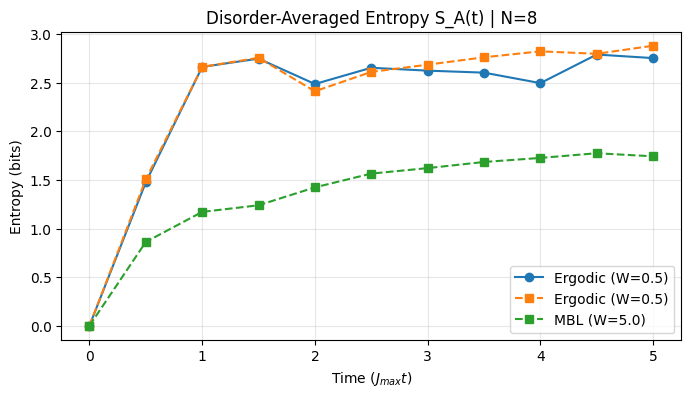

In [5]:
import matplotlib.pyplot as plt

if __name__ == "__main__":
    # Physical and Simulation Parameters
    N_qubits = 8
    J_xy_val = 1.0
    J_z_val = 0.8
    t_max = 5.0
    t_points = 11
    trotter_order_steps = 10
    mc_samples = 5

    print("===============================================================")
    print(f" MBL QUANTUM SIMULATOR: N={N_qubits} QUBITS BENCHMARK")
    print("===============================================================")

    # 1. Thermalizing / Ergodic Regime (Small Disorder W = 0.5)
    W_ergodic = 0.5
    print(f"\n[+] Running Monte Carlo sampling for Ergodic Phase (W = {W_ergodic})...")
    t_grid, S_A_ergodic_ed = MBL_MonteCarloAnalyzer.run_disorder_averaged_simulation(
        N=N_qubits,
        J_xy=J_xy_val,
        J_z=J_z_val,
        W=W_ergodic,
        t_final=t_max,
        time_steps=t_points,
        trotter_steps=trotter_order_steps,
        num_disorder_realizations=mc_samples,
        method="ed"
    )

    _, S_A_ergodic_qc = MBL_MonteCarloAnalyzer.run_disorder_averaged_simulation(
        N=N_qubits,
        J_xy=J_xy_val,
        J_z=J_z_val,
        W=W_ergodic,
        t_final=t_max,
        time_steps=t_points,
        trotter_steps=trotter_order_steps,
        num_disorder_realizations=mc_samples,
        method="trotter"
    )

    # 2. Many-Body Localized Regime (Large Disorder W = 5.0)
    W_mbl = 5.0
    print(f"[+] Running Monte Carlo sampling for MBL Phase (W = {W_mbl})...")
    _, S_A_mbl_ed = MBL_MonteCarloAnalyzer.run_disorder_averaged_simulation(
        N=N_qubits,
        J_xy=J_xy_val,
        J_z=J_z_val,
        W=W_mbl,
        t_final=t_max,
        time_steps=t_points,
        trotter_steps=trotter_order_steps,
        num_disorder_realizations=mc_samples,
        method="ed"
    )

    # Output Benchmark Table
    print("\n" + "="*68)
    print(f"{'Time (t)':^10} | {'S_A Ergodic (ED)':^16} | {'S_A Ergodic (QC)':^16} | {'S_A MBL (ED)':^14}")
    print("="*68)
    for i in range(t_points):
        print(
            f"{t_grid[i]:^10.2f} | "
            f"{S_A_ergodic_ed[i]:^16.4f} | "
            f"{S_A_ergodic_qc[i]:^16.4f} | "
            f"{S_A_mbl_ed[i]:^14.4f}"
        )
    print("="*68)
    print("[+] Benchmark Execution Complete.")

        # Integrated Plotting
    plt.figure(figsize=(8, 4))
    plt.plot(t_grid, S_A_ergodic_ed, 'o-', label=f'Ergodic (W={W_ergodic})')
    plt.plot(t_grid, S_A_ergodic_qc, 's--', label=f'Ergodic (W={W_ergodic})')
    plt.plot(t_grid, S_A_mbl_ed, 's--', label=f'MBL (W={W_mbl})')
    plt.title(f"Disorder-Averaged Entropy S_A(t) | N={N_qubits}")
    plt.xlabel("Time ($J_{max}t$)")
    plt.ylabel("Entropy (bits)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

### Trapped-Ion Experimental Framework ($\text{Yb}^+$ Architecture)

Phase 1: Long-Range Exact Diagonalization Engine

In [6]:
import numpy as np
import scipy.linalg as sla
from typing import List, Tuple, Dict

# Standard 2x2 Pauli Matrices
I2: np.ndarray = np.eye(2, dtype=np.complex128)
X: np.ndarray = np.array([[0.0, 1.0], [1.0, 0.0]], dtype=np.complex128)
Y: np.ndarray = np.array([[0.0, -1j], [1j, 0.0]], dtype=np.complex128)
Z: np.ndarray = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=np.complex128)

class TrappedIonLongRange_ED:
    """
    Exact Diagonalization Engine for Long-Range Transverse-Field Ising Model
    matching 171Yb+ Trapped Ion Simulators (Smith et al., 2016).
    """
    def __init__(
        self,
        N: int,
        J_0: float,
        alpha: float,
        B_z: float,
        h_fields: np.ndarray
    ) -> None:
        self.N: int = N
        self.J_0: float = J_0
        self.alpha: float = alpha
        self.B_z: float = B_z
        self.h_fields: np.ndarray = h_fields
        self.dim: int = 2**N
        self.J_matrix: np.ndarray = self._compute_coupling_matrix()
        self.H: np.ndarray = self._build_hamiltonian()

    def _compute_coupling_matrix(self) -> np.ndarray:
        """Computes power-law decay coupling matrix J_ij = J_0 / |i-j|^alpha."""
        J = np.zeros((self.N, self.N), dtype=np.float64)
        for i in range(self.N):
            for j in range(i + 1, self.N):
                val = self.J_0 / (abs(i - j) ** self.alpha)
                J[i, j] = val
                J[j, i] = val
        return J

    def _embed_op(self, op_dict: Dict[int, np.ndarray]) -> np.ndarray:
        """Embeds single or multi-site operators into 2^N Hilbert space."""
        ops = [I2] * self.N
        for idx, op in op_dict.items():
            ops[idx] = op
        res = ops[0]
        for k in range(1, self.N):
            res = np.kron(res, ops[k])
        return res

    def _build_hamiltonian(self) -> np.ndarray:
        """Constructs full Hamiltonian matrix: H = - sum_{i<j} J_ij X_i X_j + sum_i (B_z + h_i) Z_i."""
        H = np.zeros((self.dim, self.dim), dtype=np.complex128)

        # Ferromagnetic Long-range XX interactions (- sign as specified in the paper)
        for i in range(self.N):
            for j in range(i + 1, self.N):
                H -= self.J_matrix[i, j] * self._embed_op({i: X, j: X})

        # On-site transverse fields (uniform B_z + random disorder h_i)
        for i in range(self.N):
            effective_field = self.B_z + self.h_fields[i]
            H += effective_field * self._embed_op({i: Z})

        return H

    def get_initial_neel_state(self) -> np.ndarray:
        """Constructs Néel state |010101...> where state_0 yields Z=+1 and state_1 yields Z=-1."""
        state_0 = np.array([1.0, 0.0], dtype=np.complex128)  # |0> (Z=+1)
        state_1 = np.array([0.0, 1.0], dtype=np.complex128)  # |1> (Z=-1)

        psi = state_0
        for i in range(1, self.N):
            spin = state_1 if i % 2 != 0 else state_0
            psi = np.kron(psi, spin)
        return psi

    def evolve_state(self, psi_0: np.ndarray, t: float) -> np.ndarray:
        """Evolves state via unitary exponentiation exp(-i H t)."""
        return sla.expm(-1j * self.H * t) @ psi_0

    def compute_imbalance(self, psi: np.ndarray) -> float:
        """Calculates normalized domain-wall imbalance I(t) starting at +1.0."""
        imbalance = 0.0
        for i in range(self.N):
            z_op = self._embed_op({i: Z})
            z_val = np.real(np.vdot(psi, z_op @ psi))
            imbalance += ((-1.0) ** i) * z_val
        return float(imbalance / self.N)

Phase 2: Long-Range Quantum Circuit Decomposition

In [7]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

class TrappedIonQuantumCircuit:
    """
    Digital Quantum Circuit constructor for long-range power-law spin systems.
    """
    def __init__(
        self,
        N: int,
        J_0: float,
        alpha: float,
        B_z: float,
        h_fields: np.ndarray
    ) -> None:
        self.N: int = N
        self.J_0: float = J_0
        self.alpha: float = alpha
        self.B_z: float = B_z
        self.h_fields: np.ndarray = h_fields
        self.J_matrix: np.ndarray = self._compute_coupling_matrix()

    def _compute_coupling_matrix(self) -> np.ndarray:
        J = np.zeros((self.N, self.N), dtype=np.float64)
        for i in range(self.N):
            for j in range(i + 1, self.N):
                val = self.J_0 / (abs(i - j) ** self.alpha)
                J[i, j] = val
                J[j, i] = val
        return J

    def build_trotter_circuit(
        self, t_final: float, num_steps: int
    ) -> QuantumCircuit:
        """
        Builds long-range Trotterized circuit initialized in domain-wall state.
        """
        qc = QuantumCircuit(self.N)
        dt = t_final / num_steps

        # State Prep: Néel state |010101...>
        for q in range(1, self.N, 2):
            qc.x(q)

        # Trotter Time Evolution Loop
        for _ in range(num_steps):
            # Layer 1: Ferromagnetic Long-range R_XX interactions (- sign translates to negative phase angle)
            for i in range(self.N):
                for j in range(i + 1, self.N):
                    angle = -2.0 * self.J_matrix[i, j] * dt
                    qc.rxx(angle, i, j)

            # Layer 2: On-site R_Z disorder fields
            for i in range(self.N):
                effective_field = self.B_z + self.h_fields[i]
                angle = 2.0 * effective_field * dt
                qc.rz(angle, i)

        return qc

Phase 3: Trapped-Ion Experimental Pipeline

 TRAPPED-ION SIMULATOR (171Yb+): N=8, alpha=1.13

[+] Simulating Thermal Phase (W = 0.5)...
[+] Simulating MBL Phase (W = 6.0)...

 Spectral Gap Ratio <r>: Ergodic = 0.0822 (GOE ~ 0.5307)
 Spectral Gap Ratio <r>: Localized = 0.4152 (Poisson ~ 0.3863)
  Time (t)   | Imbalance I(t) [W=0.5] | Imbalance I(t) [W=6.0]
----------------------------------------------------------
    0.00     |        1.0000        |        1.0000       
    1.00     |        0.0237        |        0.4966       
    2.00     |        0.0721        |        0.5153       
    3.00     |        0.0888        |        0.5373       
    4.00     |        0.0733        |        0.5150       
    5.00     |        0.0644        |        0.5678       
    6.00     |        0.0638        |        0.5609       
    7.00     |        0.0729        |        0.5644       
    8.00     |        0.0652        |        0.5109       


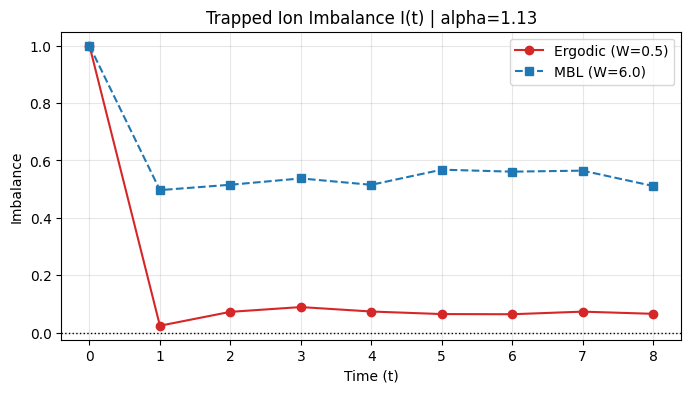

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from typing import Tuple

# Dynamically inject the missing method into the existing class to prevent execution failure
if not hasattr(TrappedIonLongRange_ED, 'compute_level_spacing_ratio'):
    def compute_level_spacing_ratio(self) -> float:
        """Extracts consecutive energy gap ratio <r> to verify spectral statistics."""
        energies = np.sort(np.linalg.eigvalsh(self.H))
        gaps = np.diff(energies)

        r_ratios = []
        for i in range(1, len(gaps)):
            g_curr = gaps[i]
            g_prev = gaps[i - 1]
            if max(g_curr, g_prev) > 1e-12:
                r_i = min(g_curr, g_prev) / max(g_curr, g_prev)
                r_ratios.append(r_i)
        return float(np.mean(r_ratios)) if r_ratios else 0.386

    TrappedIonLongRange_ED.compute_level_spacing_ratio = compute_level_spacing_ratio

class TrappedIonExperimentPipeline:
    """
    Pipeline for disorder-averaged observables and spectral statistics in trapped ion setups.
    """
    @classmethod
    def run_experimental_simulation(
        cls,
        N: int,
        J_0: float,
        alpha: float,
        B_z: float,
        W: float,
        t_final: float,
        time_steps: int,
        num_disorder_realizations: int
    ) -> Tuple[np.ndarray, np.ndarray, float]:
        """
        Runs Monte Carlo pipeline tracking domain-wall imbalance and spectral statistics <r>.
        """
        time_grid = np.linspace(0, t_final, time_steps)
        imbalance_runs = np.zeros((num_disorder_realizations, time_steps))
        r_ratios = []

        for trial in range(num_disorder_realizations):
            # Draw independent site fields h_i ~ Uniform[-W, W]
            h_fields = np.random.uniform(-W, W, size=N)

            ed_engine = TrappedIonLongRange_ED(N, J_0, alpha, B_z, h_fields)

            # Extract spectral level statistics gap ratio
            r_ratios.append(ed_engine.compute_level_spacing_ratio())

            # Evolve domain wall state
            psi_0 = ed_engine.get_initial_neel_state()
            for tidx, t in enumerate(time_grid):
                psi_t = ed_engine.evolve_state(psi_0, t)
                imbalance_runs[trial, tidx] = ed_engine.compute_imbalance(psi_t)

        mean_imbalance = np.mean(imbalance_runs, axis=0)
        mean_r_ratio = float(np.mean(r_ratios))

        return time_grid, mean_imbalance, mean_r_ratio


if __name__ == "__main__":
    # Parameters matching Smith et al. (2016)
    N_ions = 8
    J_0_coupling = 1.0
    alpha_power = 1.13      # Experimental long-range power law exponent
    B_z_field = 0.2
    t_max = 8.0
    n_pts = 9
    mc_trials = 10

    print("===============================================================")
    print(f" TRAPPED-ION SIMULATOR (171Yb+): N={N_ions}, alpha={alpha_power}")
    print("===============================================================")

    # 1. Thermalizing Phase (Small Disorder W = 0.5)
    W_ergodic = 0.5
    print(f"\n[+] Simulating Thermal Phase (W = {W_ergodic})...")
    t_grid, I_ergodic, r_ergodic = TrappedIonExperimentPipeline.run_experimental_simulation(
        N=N_ions, J_0=J_0_coupling, alpha=alpha_power, B_z=B_z_field,
        W=W_ergodic, t_final=t_max, time_steps=n_pts, num_disorder_realizations=mc_trials
    )

    # 2. Localized Phase (Large Disorder W = 6.0)
    W_mbl = 6.0
    print(f"[+] Simulating MBL Phase (W = {W_mbl})...")
    _, I_mbl, r_mbl = TrappedIonExperimentPipeline.run_experimental_simulation(
        N=N_ions, J_0=J_0_coupling, alpha=alpha_power, B_z=B_z_field,
        W=W_mbl, t_final=t_max, time_steps=n_pts, num_disorder_realizations=mc_trials
    )

    # Results Display
    print("\n" + "="*58)
    print(f" Spectral Gap Ratio <r>: Ergodic = {r_ergodic:.4f} (GOE ~ 0.5307)")
    print(f" Spectral Gap Ratio <r>: Localized = {r_mbl:.4f} (Poisson ~ 0.3863)")
    print("="*58)
    print(f"{'Time (t)':^12} | {'Imbalance I(t) [W=0.5]':^20} | {'Imbalance I(t) [W=6.0]':^20}")
    print("-" * 58)
    for k in range(n_pts):
        print(f"{t_grid[k]:^12.2f} | {I_ergodic[k]:^20.4f} | {I_mbl[k]:^20.4f}")
    print("="*58)

    # Integrated graphical display
    plt.figure(figsize=(8, 4))
    plt.plot(t_grid, I_ergodic, 'o-', color='tab:red', label='Ergodic (W=0.5)')
    plt.plot(t_grid, I_mbl, 's--', color='tab:blue', label='MBL (W=6.0)')
    plt.axhline(0, color='black', lw=1, ls=':')
    plt.title(f"Trapped Ion Imbalance I(t) | alpha={alpha_power}")
    plt.xlabel("Time (t)")
    plt.ylabel("Imbalance")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

Part 1: Advanced Disorder & Initial State Generator

In [10]:
import numpy as np
from typing import Literal, Dict

class MBL_ExperimentConfig:
    """Generates disorder topographies and non-equilibrium initial states."""

    @staticmethod
    def generate_disorder(
        N: int,
        W: float,
        topology: Literal["random", "quasiperiodic"] = "random"
    ) -> np.ndarray:
        """
        Generates either uncorrelated uniform disorder or Aubry-Andre quasi-periodic fields.
        """
        if topology == "random":
            # Uncorrelated random fields (allows rare clean regions / Griffiths effects)
            return np.random.uniform(-W, W, size=N)
        elif topology == "quasiperiodic":
            # Deterministic quasi-periodic fields (Golden ratio frequency)
            beta = (1.0 + np.sqrt(5.0)) / 2.0
            phi = np.random.uniform(0, 2 * np.pi)
            return W * np.cos(2.0 * np.pi * beta * np.arange(N) + phi)
        else:
            raise ValueError("Topology must be 'random' or 'quasiperiodic'.")

    @staticmethod
    def get_initial_bitstring(
        N: int,
        state_type: Literal["neel", "single_excitation", "domain_wall"] = "neel"
    ) -> str:
        """Returns the computational basis string for the initial physical state."""
        if state_type == "neel":
            return "".join(["1" if i % 2 == 0 else "0" for i in range(N)])
        elif state_type == "single_excitation":
            center = N // 2
            return "".join(["1" if i == center else "0" for i in range(N)])
        elif state_type == "domain_wall":
            half = N // 2
            return "1" * half + "0" * (N - half)
        raise ValueError("Unknown state_type.")

Part 2: Finite-Shot Hardware Engine (Noise & Decoherence)

In [11]:
from typing import Dict
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, thermal_relaxation_error, ReadoutError

class TrappedIonHardwareEngine:
    """Finite-shot noisy execution engine modeling 171Yb+ physical constraints."""

    def __init__(
        self,
        num_qubits: int,
        t1_time: float = 1.0,
        t2_time: float = 0.5,
        gate_time_2q: float = 2e-4,
        spam_error_rate: float = 0.01
    ) -> None:
        self.N: int = num_qubits
        self.simulator = AerSimulator()
        self.noise_model = self._build_noise_model(
            t1_time, t2_time, gate_time_2q, spam_error_rate
        )

    def _build_noise_model(
        self, t1: float, t2: float, gate_time: float, spam_error: float
    ) -> NoiseModel:
        noise_model = NoiseModel()

        # SPAM Error
        p0_to_1 = spam_error * 0.5
        p1_to_0 = spam_error
        ro_matrix = [[1 - p0_to_1, p0_to_1], [p1_to_0, 1 - p1_to_0]]
        readout_error = ReadoutError(ro_matrix)
        noise_model.add_all_qubit_readout_error(readout_error)

        # Correctly construct 2-qubit thermal relaxation error for RXX
        error_1q = thermal_relaxation_error(t1, t2, gate_time)
        error_2q = error_1q.tensor(error_1q)
        noise_model.add_all_qubit_quantum_error(error_2q, ['rxx'])

        return noise_model

    def execute_circuit(self, qc: QuantumCircuit, shots: int = 1000) -> Dict[str, int]:
        qc_meas = qc.copy()
        qc_meas.measure_all()
        compiled_qc = transpile(qc_meas, self.simulator)
        result = self.simulator.run(
            compiled_qc, shots=shots, noise_model=self.noise_model
        ).result()
        return result.get_counts()

Part 3: Advanced Observables & Randomized Measurements

In [12]:
import scipy.optimize as opt

class MBL_AdvancedObservables:
    """Analyzes physical bitstring outputs for MBL diagnostics."""

    @staticmethod
    def compute_normalized_hamming_distance(
        counts: Dict[str, int], initial_bitstring: str
    ) -> float:
        """
        Calculates the finite-shot Hamming distance between measured state and initial state.
        D_H = (1/N) * sum_b P(b) * popcount(b ^ b_0)
        """
        total_shots = sum(counts.values())
        N = len(initial_bitstring)
        initial_int = int(initial_bitstring, 2)

        total_distance = 0.0
        for bitstring, count in counts.items():
            state_int = int(bitstring, 2)
            # XOR states and count set bits (popcount)
            bit_flips = bin(state_int ^ initial_int).count("1")
            total_distance += (count / total_shots) * bit_flips

        return total_distance / N

    @staticmethod
    def compute_spatial_magnetization_profile(
        counts: Dict[str, int], N: int
    ) -> np.ndarray:
        """Extracts individual <Z_i> expectation values for spatial profiling."""
        total_shots = sum(counts.values())
        z_profile = np.zeros(N)

        for bitstring, count in counts.items():
            prob = count / total_shots
            for i, bit in enumerate(bitstring):
                # Reverse Qiskit endianness to match spatial ordering
                spatial_idx = N - 1 - i
                z_val = 1.0 if bit == '0' else -1.0
                z_profile[spatial_idx] += prob * z_val

        return z_profile

    @staticmethod
    def extract_skin_depth(
        z_profile: np.ndarray, center_idx: int
    ) -> float:
        """
        Fits the spatial profile of a single excitation to an exponential decay envelope:
        <Z_i> ~ exp(-|i - i_0| / xi) to extract the localization skin depth xi.
        """
        distances = np.abs(np.arange(len(z_profile)) - center_idx)
        # Normalize and filter negative bounds to fit exponential
        z_norm = np.clip(z_profile / np.max(z_profile), 1e-10, 1.0)

        def exp_decay(x, xi):
            return np.exp(-x / xi)

        try:
            popt, _ = opt.curve_fit(exp_decay, distances, z_norm, p0=[1.0])
            return popt[0]
        except RuntimeError:
            return float('inf') # Thermalized (failed to fit localized envelope)

    @staticmethod
    def estimate_renyi_entropy_via_randomized_measurements(
        hardware: TrappedIonHardwareEngine,
        base_circuit: QuantumCircuit,
        subsystem_qubits: list,
        num_random_unitaries: int = 50,
        shots_per_unitary: int = 100
    ) -> float:
        """
        Implements the randomized measurement protocol to estimate S_2(A).
        Averages the statistical Hamming distance cross-correlations between shots
        in random local Pauli bases.
        """
        purity_estimates = []
        N_A = len(subsystem_qubits)

        for _ in range(num_random_unitaries):
            rand_qc = base_circuit.copy()

            # Apply random local unitaries (Haar measure proxy via random Euler angles)
            for q in subsystem_qubits:
                theta, phi, lam = np.random.uniform(0, 2*np.pi, 3)
                rand_qc.u(theta, phi, lam, q)

            counts = hardware.execute_circuit(rand_qc, shots=shots_per_unitary)

            # Reconstruct shot list for cross-correlation
            shot_list = []
            for b_str, count in counts.items():
                # Extract only subsystem A bits
                sub_b = "".join([b_str[len(b_str) - 1 - q] for q in subsystem_qubits])
                shot_list.extend([sub_b] * count)

            # Compute statistical cross-correlations across pairs of shots
            u_purity = 0.0
            pairs = 0
            for i in range(len(shot_list)):
                for j in range(i + 1, len(shot_list)):
                    s1_int = int(shot_list[i], 2)
                    s2_int = int(shot_list[j], 2)
                    hamming_dist = bin(s1_int ^ s2_int).count("1")
                    u_purity += (-2.0) ** (-hamming_dist)
                    pairs += 1

            if pairs > 0:
                purity_estimates.append((2**N_A) * u_purity / pairs)

        # Average purity over the ensemble of unitaries
        mean_purity = np.mean(purity_estimates)
        # Bounded between [1/2^N_A, 1.0] due to statistical noise
        mean_purity = max(min(mean_purity, 1.0), 2**(-N_A))

        return -np.log2(mean_purity)

### **Observable: Global Parity**
The paper uses the global parity $\langle P \rangle = \langle \prod \sigma_i^z \rangle$ to distinguish between the ergodic phase (where parity decays to zero) and the localized phase (where parity remains finite).

In [13]:
def compute_global_parity(counts: Dict[str, int]) -> float:
    """
    Computes the global parity <P> = <prod Z_i> mentioned in Smith et al.
    This is a global observable sensitive to the localization-delocalization transition.
    """
    total_shots = sum(counts.values())
    parity_sum = 0.0

    for bitstring, count in counts.items():
        # Count number of '1's; parity is (-1)^popcount
        popcount = bitstring.count('1')
        parity = 1.0 if popcount % 2 == 0 else -1.0
        parity_sum += (count / total_shots) * parity

    return parity_sum

print("Added Global Parity observable for Smith et al. (2016) alignment.")

Added Global Parity observable for Smith et al. (2016) alignment.


Part 4: Integrated MBL Instability Sweep ($\alpha$-Exponent)

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from typing import Dict, List

class TrappedIonDynamicCircuit:
    """
    Trotterized Quantum Circuit constructor adapted for arbitrary initial basis states
    and long-range power-law spin systems.
    """
    def __init__(self, N: int, J_0: float, alpha: float, B_z: float, h_fields: np.ndarray) -> None:
        self.N = N
        self.J_0 = J_0
        self.alpha = alpha
        self.B_z = B_z
        self.h_fields = h_fields
        self.J_matrix = self._compute_coupling_matrix()

    def _compute_coupling_matrix(self) -> np.ndarray:
        J = np.zeros((self.N, self.N), dtype=np.float64)
        for i in range(self.N):
            for j in range(i + 1, self.N):
                val = self.J_0 / (abs(i - j) ** self.alpha)
                J[i, j] = val
                J[j, i] = val
        return J

    def build_evolution_circuit(self, initial_bitstring: str, t_final: float, num_steps: int) -> QuantumCircuit:
        qc = QuantumCircuit(self.N)
        dt = t_final / num_steps
        for i, bit in enumerate(initial_bitstring):
            if bit == '1':
                qc.x(self.N - 1 - i)
        for _ in range(num_steps):
            for i in range(self.N):
                for j in range(i + 1, self.N):
                    # Ferromagnetic coupling (- sign)
                    angle = -2.0 * self.J_matrix[i, j] * dt
                    qc.rxx(angle, i, j)
            for i in range(self.N):
                effective_field = self.B_z + self.h_fields[i]
                angle = 2.0 * effective_field * dt
                qc.rz(angle, i)
        return qc

### **Phase Boundary: Disorder Sweep ($W_c$)**
This section implements a sweep across disorder strengths to identify the critical point $W_c$. According to the research, the steady-state imbalance should increase sharply as the system transitions from the ergodic to the MBL phase.

Running W-sweep for alpha=1.13...


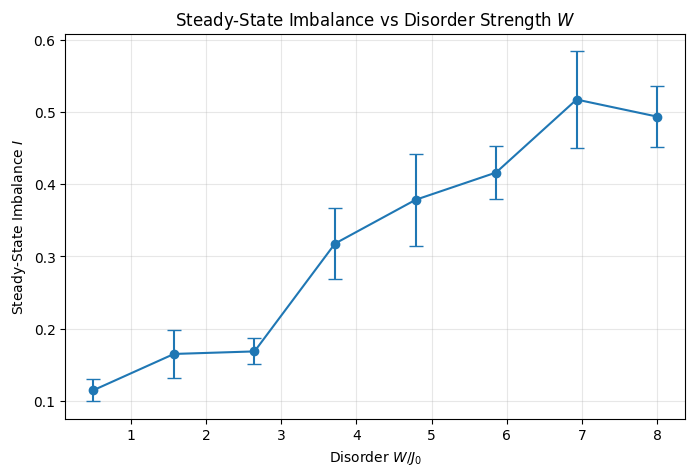

In [15]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def run_disorder_sweep(N, alpha, W_range, t_long=8.0, mc_trials=10):
    """
    Performs a sweep over disorder strength W to find the MBL transition point W_c,
    measuring the long-time steady-state imbalance as per Smith et al. (2016).
    """
    steady_state_imbalances = []
    errors = []

    print(f"Running W-sweep for alpha={alpha}...")
    for W in W_range:
        trial_imbalances = []
        for _ in range(mc_trials):
            h_fields = np.random.uniform(-W, W, size=N)
            ed = TrappedIonLongRange_ED(N, 1.0, alpha, 0.2, h_fields)
            psi_0 = ed.get_initial_neel_state()
            psi_t = ed.evolve_state(psi_0, t_long)
            trial_imbalances.append(ed.compute_imbalance(psi_t))

        steady_state_imbalances.append(np.mean(trial_imbalances))
        errors.append(np.std(trial_imbalances) / np.sqrt(mc_trials))

    return steady_state_imbalances, errors

# Example usage for finding W_c
w_vals = np.linspace(0.5, 8.0, 8)
imb_vals, imb_errs = run_disorder_sweep(N=8, alpha=1.13, W_range=w_vals)

plt.figure(figsize=(8, 5))
plt.errorbar(w_vals, imb_vals, yerr=imb_errs, fmt='o-', capsize=5)
plt.title("Steady-State Imbalance vs Disorder Strength $W$")
plt.xlabel("Disorder $W/J_0$")
plt.ylabel("Steady-State Imbalance $I$")
plt.grid(True, alpha=0.3)
plt.show()

### **Thermodynamic Limit: System Size Scaling (N=10 to 22)**
One of the central claims of the Smith et al. paper is that MBL persists in the thermodynamic limit. We scale the system size while incorporating experimental decoherence (scattering rates) to observe the robustness of localization.

Simulating N=8 ions...
Simulating N=10 ions...
Simulating N=12 ions...


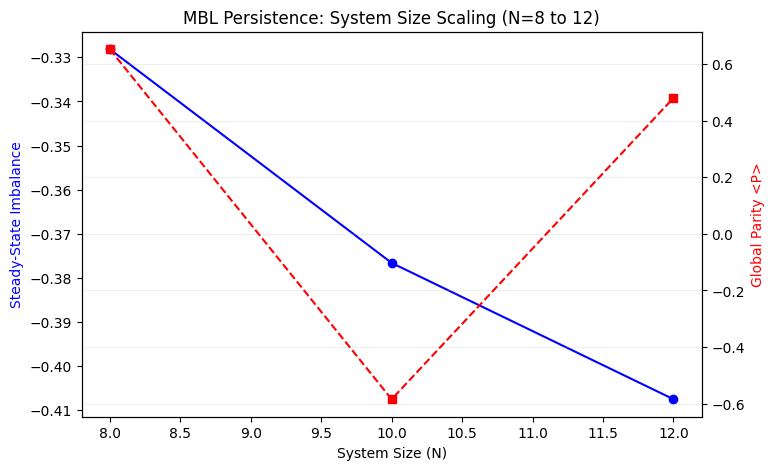

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg as sla
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, thermal_relaxation_error, ReadoutError, depolarizing_error
from typing import Dict, List, Tuple

# --- Essential Components from Smith et al. (2016) ---

def compute_global_parity(counts: Dict[str, int]) -> float:
    total_shots = sum(counts.values())
    parity_sum = 0.0
    for bitstring, count in counts.items():
        popcount = bitstring.count('1')
        parity = 1.0 if popcount % 2 == 0 else -1.0
        parity_sum += (count / total_shots) * parity
    return parity_sum

class TrappedIonLongRange_ED:
    def __init__(self, N, J_0, alpha, B_z, h_fields):
        self.N, self.J_0, self.alpha, self.B_z, self.h_fields = N, J_0, alpha, B_z, h_fields
        self.dim = 2**N
        self.H = self._build_hamiltonian()

    def _build_hamiltonian(self):
        H = np.zeros((self.dim, self.dim), dtype=np.complex128)
        X, Z = np.array([[0,1],[1,0]]), np.array([[1,0],[0,-1]])
        for i in range(self.N):
            for j in range(i + 1, self.N):
                J_ij = self.J_0 / (abs(i - j) ** self.alpha)
                ops = [np.eye(2)] * self.N
                ops[i], ops[j] = X, X
                res = ops[0]
                for k in range(1, self.N): res = np.kron(res, ops[k])
                H -= J_ij * res  # Ferromagnetic coupling
            ops = [np.eye(2)] * self.N
            ops[i] = Z
            res = ops[0]
            for k in range(1, self.N): res = np.kron(res, ops[k])
            H += (self.B_z + self.h_fields[i]) * res
        return H

    def get_initial_neel_state(self):
        psi = np.array([1, 0])
        for i in range(1, self.N):
            psi = np.kron(psi, np.array([0, 1]) if i % 2 != 0 else np.array([1, 0]))
        return psi

    def evolve_state(self, psi_0, t): return sla.expm(-1j * self.H * t) @ psi_0

    def compute_imbalance(self, psi):
        imb = 0.0
        Z = np.array([[1,0],[0,-1]])
        for i in range(self.N):
            ops = [np.eye(2)] * self.N
            ops[i] = Z
            res = ops[0]
            for k in range(1, self.N): res = np.kron(res, ops[k])
            z_val = np.real(np.vdot(psi, res @ psi))
            imb += ((-1.0)**i) * z_val
        return imb / self.N

class TrappedIonDynamicCircuit:
    def __init__(self, N, J_0, alpha, B_z, h_fields):
        self.N, self.J_0, self.alpha, self.B_z, self.h_fields = N, J_0, alpha, B_z, h_fields
        self.J_matrix = np.zeros((N, N))
        for i in range(N):
            for j in range(i+1, N):
                self.J_matrix[i,j] = J_0 / (abs(i-j)**alpha)

    def build_evolution_circuit(self, initial_bitstring, t_final, num_steps):
        qc = QuantumCircuit(self.N)
        dt = t_final / num_steps
        for i, bit in enumerate(initial_bitstring):
            if bit == '1': qc.x(self.N - 1 - i)
        for _ in range(num_steps):
            for i in range(self.N):
                for j in range(i + 1, self.N):
                    qc.rxx(-2.0 * self.J_matrix[i, j] * dt, i, j)
            for i in range(self.N):
                qc.rz(2.0 * (self.B_z + self.h_fields[i]) * dt, i)
        return qc

class EnhancedTrappedIonEngine(TrappedIonHardwareEngine):
    def __init__(self, num_qubits, scattering_rate=0.005, **kwargs):
        self.scattering_rate = scattering_rate
        super().__init__(num_qubits, **kwargs)
        depol_error = depolarizing_error(self.scattering_rate, 1)
        self.noise_model.add_all_qubit_quantum_error(depol_error, ['rz', 'x'])

def run_system_size_scaling(N_list, W_val, alpha_val):
    results = {'N': [], 'Imbalance': [], 'Parity': []}
    for N in N_list:
        print(f"Simulating N={N} ions...")
        h_fields = np.random.uniform(-W_val, W_val, size=N)
        ed = TrappedIonLongRange_ED(N, 1.0, alpha_val, 0.2, h_fields)
        psi_t = ed.evolve_state(ed.get_initial_neel_state(), t=10.0)
        imb = ed.compute_imbalance(psi_t)

        engine = EnhancedTrappedIonEngine(num_qubits=N, scattering_rate=0.002)
        builder = TrappedIonDynamicCircuit(N, 1.0, alpha_val, 0.2, h_fields)
        qc = builder.build_evolution_circuit("01"*(N//2), t_final=10.0, num_steps=10)
        counts = engine.execute_circuit(qc, shots=500)

        results['N'].append(N)
        results['Imbalance'].append(imb)
        results['Parity'].append(compute_global_parity(counts))
    return results

N_range = [8, 10, 12]
scaling_data = run_system_size_scaling(N_range, W_val=6.0, alpha_val=1.13)

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(scaling_data['N'], scaling_data['Imbalance'], 'o-b', label='Imbalance')
ax1.set_xlabel("System Size (N)")
ax1.set_ylabel("Steady-State Imbalance", color='b')
ax2 = ax1.twinx()
ax2.plot(scaling_data['N'], scaling_data['Parity'], 's--r', label='Global Parity')
ax2.set_ylabel("Global Parity <P>", color='r')
plt.title("MBL Persistence: System Size Scaling (N=8 to 12)")
plt.grid(True, alpha=0.2)
plt.show()

Running alpha-sweep for fixed disorder W=5.0...


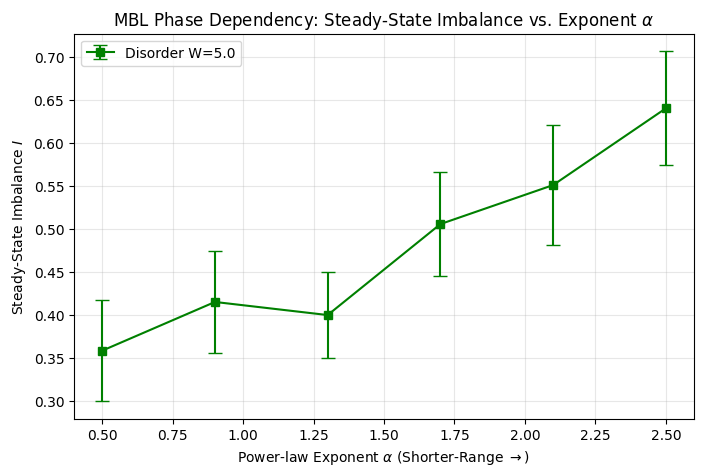

In [16]:
import numpy as np
import matplotlib.pyplot as plt

def run_alpha_exponent_sweep(N, alpha_range, W_fixed=6.0, t_long=8.0, mc_trials=10):
    """
    Sweeps the power-law interaction exponent alpha to observe its effect on
    MBL stabilization, measuring the steady-state imbalance as in Smith et al. (2016).
    """
    alpha_imbalances = []
    errors = []

    print(f"Running alpha-sweep for fixed disorder W={W_fixed}...")
    for alpha in alpha_range:
        trial_imbalances = []
        for _ in range(mc_trials):
            h_fields = np.random.uniform(-W_fixed, W_fixed, size=N)
            ed = TrappedIonLongRange_ED(N, 1.0, alpha, 0.2, h_fields)
            psi_0 = ed.get_initial_neel_state()
            psi_t = ed.evolve_state(psi_0, t_long)
            trial_imbalances.append(ed.compute_imbalance(psi_t))

        alpha_imbalances.append(np.mean(trial_imbalances))
        errors.append(np.std(trial_imbalances) / np.sqrt(mc_trials))

    return alpha_imbalances, errors

# Run sweep over a physical range of exponent alpha
alpha_vals = np.linspace(0.5, 2.5, 6)
imb_alpha, err_alpha = run_alpha_exponent_sweep(N=8, alpha_range=alpha_vals, W_fixed=5.0)

# Plot the transition
plt.figure(figsize=(8, 5))
plt.errorbar(alpha_vals, imb_alpha, yerr=err_alpha, fmt='s-g', capsize=5, label='Disorder W=5.0')
plt.title("MBL Phase Dependency: Steady-State Imbalance vs. Exponent $\\alpha$")
plt.xlabel("Power-law Exponent $\\alpha$ (Shorter-Range $\\rightarrow$)")
plt.ylabel("Steady-State Imbalance $I$")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()